# Dinámica inmobiliaria en el Eje Cafetero
## Parte III – Primer entendimiento de los datos

Este notebook reemplaza la versión exploratoria inicial del proyecto. Trabaja sobre la **base limpia oficial** (descarga del 13 de noviembre de 2026, generada con `src/igac_inmobiliario/pipeline.py`) y no vuelve a descargar ni a recalcular cifras de calidad: esas se documentan en la Parte I y quedan en `data/processed/perfil_calidad_completo.json`.

El propósito es el mismo definido en las Entregas 2 y 3: entender los registros de compraventas que pueden servir como referencia para el **Observatorio Inmobiliario Catastral (OIC) del IGAC**, como insumo para estimar un valor esperado por compraventa y priorizar para revisión las que se aparten de él.

| Elemento | Decisión del proyecto |
|---|---|
| Territorio | Caldas, Risaralda y Quindío |
| Periodo | 2015–2023, como línea base del mercado previo al sismo del 10 de agosto de 2026 |
| Operación | Compraventa, código 125 (verificado en la Parte I: 85% de los actos de compraventa; los demás transfieren fracciones o derechos parciales) |
| Unidad de registro | Anotación sobre un folio de matrícula inmobiliaria |
| Unidad territorial mínima | Municipio (sin número catastral, área, tipo de inmueble ni estrato) |

## Conceptos clave para interpretar los datos

- **Registro administrativo:** cada fila es un acto inscrito sobre un folio, no necesariamente un inmueble único ni una operación de mercado completa.
- **`matricula`:** folio de matrícula inmobiliaria. Trae el código de la oficina de registro (`290-109602`), por lo que identifica el folio sin ambigüedad entre oficinas.
- **`pk`:** se compone de DIVIPOLA, oficina, matrícula, número de anotación, código del acto y año. Como incluye el año, una misma anotación repetida en dos años tiene `pk` distintos.
- **`valor`:** valor declarado en la escritura. **No es el valor comercial** del inmueble y está en pesos corrientes.
- **`fecha_escritura`:** fecha de firma de la escritura, extraída del documento justificativo (legible en el 100% de los registros). Es la fecha que corresponde al valor declarado; la fecha de radicación está vacía en el 85% de la base.
- **`escritura_paquete` / `valor_repetido_en_paquete`:** la escritura transfiere varios folios; en el segundo caso, cada folio lleva el valor total del negocio, no su precio individual.
- **`escritura_rezagada`:** dos o más años entre la escritura y la radicación; su valor corresponde a otra época.
- **`incluido_universo_modelado`:** valor válido, sin duplicados y sin valor simbólico.

## Riesgos que se controlan en esta etapa

La RBS y el AMEF de la Entrega 3 identifican riesgos que afectan directamente el entendimiento de los datos:

- **Identificación:** una matrícula inconsistente o folios derivados pueden impedir reconocer correctamente las ventas repetidas.
- **Calidad:** valores simbólicos, duplicados y escrituras que agrupan varios inmuebles distorsionan las referencias. Aquí se usan las banderas de la limpieza en lugar de redefinirlas.
- **Temporalidad:** usar información futura para explicar una transacción pasada produciría fuga de información; los análisis respetan el orden de la fecha de la escritura.
- **Comparabilidad:** sin área ni tipo de inmueble, los niveles de valor entre municipios **no son comparables directamente**; las diferencias reflejan también la composición de lo que se vende.

In [1]:
# Configuración y carga de la base limpia oficial
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Ubicar la raíz del repo (la carpeta que contiene src/), sin importar desde dónde se abra
RAIZ = Path.cwd()
while not (RAIZ / "src").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

d = pd.read_csv(RAIZ / "data/processed/compraventas_eje_cafetero_completo_limpio.csv", dtype=str)
for col in ["valor", "valor_relativo_mediana"]:
    d[col] = pd.to_numeric(d[col])
for col in ["year_radica", "rezago_escritura_anios", "folios_en_escritura", "num_anotacion"]:
    d[col] = pd.to_numeric(d[col]).astype("Int64")
d["fecha_escritura"] = pd.to_datetime(d["fecha_escritura"])
d["anio_escritura"] = d["fecha_escritura"].dt.year
banderas = [c for c in d.columns if d[c].isin(["True", "False"]).all()]
d[banderas] = d[banderas].eq("True")

ficha = json.loads((RAIZ / "data/raw/compraventas_eje_cafetero_completo_descarga.json").read_text(encoding="utf-8"))
print(f"Registros: {len(d):,}")
print(f"Descarga: {ficha['fecha_descarga_utc']} | Portal actualizado: {ficha['portal_actualizado_utc']}")

Registros: 457,558
Descarga: 2026-11-13T19:15:55+00:00 | Portal actualizado: 2025-04-04T17:58:44+00:00


## Técnicas seleccionadas para el entendimiento de los datos

De las nueve técnicas propuestas por Informs (2014), se seleccionan las que responden a la pregunta de negocio. *Justificaciones en borrador: a validar por el responsable de la Parte III.*

| Técnica | ¿Se aplica? | Justificación |
|---|---|---|
| Filtración | Sí | Delimitar el universo útil para el índice a partir de las banderas de calidad (sección 1). |
| Imputación | No | El valor faltante no se imputa: inventar un valor registrado contradice el propósito de identificar referencias confiables. |
| Reducción de dimensiones | No | Pocas variables y casi todas categóricas o de identificación. |
| Extracción de variables (features) | Sí | Ventas repetidas del mismo folio, tiempo entre ventas y cambio de valor: son el insumo del índice (sección 4). |
| Estadísticas básicas | Sí | Distribución del valor y volumen por año (sección 2). |
| Adición de nueva información | Sí | IPC para expresar valores en pesos constantes (sección 5, pendiente). |
| Segmentación | Sí | Por departamento, municipio y zona urbana o rural (sección 3). |
| Determinación de variables importantes | Pendiente | Depende del modelo de respaldo para folios sin venta repetida. |
| Clasificación o agrupación | Pendiente | Posible agrupación de municipios con dinámicas similares. |

## 1. Filtración: de la base completa a los candidatos para el índice

Cada paso aplica una bandera de la limpieza. Los cuatro primeros definen el **universo modelado**; los dos últimos son un **escenario** para el índice de ventas repetidas (excluir valores que no son precio individual y valores de otra época). Si esos dos pasos se aplican o no se decide en la Parte II.

In [2]:
pasos = [
    ("Base completa", pd.Series(True, index=d.index)),
    ("Con valor válido", d["valor_valido"]),
    ("Sin duplicados (anotación y pk)", ~d["anotacion_duplicada"] & ~d["registro_duplicado"] & d["matricula_valida"]),
    ("Sin valor simbólico", ~d["valor_simbolico"]),
    ("Valor individual (sin total repetido en paquete)", ~d["valor_repetido_en_paquete"]),
    ("Escritura contemporánea (rezago < 2 años)", ~d["escritura_rezagada"]),
]
acumulado = pd.Series(True, index=d.index)
filas = []
for nombre, condicion in pasos:
    acumulado &= condicion
    filas.append({"paso": nombre, "registros": int(acumulado.sum())})
embudo = pd.DataFrame(filas)
embudo["% de la base"] = (embudo["registros"] / len(d) * 100).round(1)
embudo["salen en el paso"] = (-embudo["registros"].diff()).fillna(0).astype(int)

universo = d["incluido_universo_modelado"]
candidatos = acumulado
assert int(universo.sum()) == int(embudo.loc[3, "registros"]), "El embudo no coincide con incluido_universo_modelado"
display(embudo)

,paso,registros,% de la base,salen en el paso
0,Base completa,457558,100.00,0
1,Con valor válido,441511,96.50,16047
2,Sin duplicados (anotación y pk),438264,95.80,3247
3,Sin valor simbólico,437648,95.60,616
4,Valor individual (sin total repetido en paquete),340967,74.50,96681
5,Escritura contemporánea (rezago < 2 años),338941,74.10,2026


## 2. Estadísticas básicas del universo modelado

Revisión estructural (función del notebook inicial) y distribución del valor. El valor se muestra en escala logarítmica por su asimetría; no se modifica el dato original. **Pesos corrientes**: las comparaciones entre años mezclan cambio de precios e inflación hasta incorporar el IPC.

In [3]:
def explorar_dataframe(df):
    return pd.DataFrame({
        "Tipo de dato": df.dtypes,
        "Valores únicos": df.nunique(dropna=True),
        "Datos válidos": df.notna().sum(),
        "Datos faltantes": df.isna().sum(),
        "% faltantes": (df.isna().mean() * 100).round(2),
    }).sort_values("% faltantes", ascending=False)

u = d[universo].copy()
display(explorar_dataframe(u))

,Tipo de dato,Valores únicos,Datos válidos,Datos faltantes,% faltantes
folios_derivados,object,47,58,437590,99.99
fecha_radica_texto,object,637,66424,371224,84.82
fecha_apertura_texto,object,21972,86979,350669,80.13
estado_folio,object,2,429862,7786,1.78
clave_escritura,object,341726,437304,344,0.08
folios_en_escritura,Int64,70,437304,344,0.08
pk,object,437648,437648,0,0.00
year_radica,Int64,9,437648,0,0.00
matricula,object,343024,437648,0,0.00
tipo_predio_zona,object,3,437648,0,0.00


,valor (millones de pesos corrientes)
count,"437,648.00"
mean,169.24
std,"4,167.84"
min,0.00
5%,3.50
25%,19.10
50%,65.00
75%,126.90
95%,328.42
max,"820,000.00"


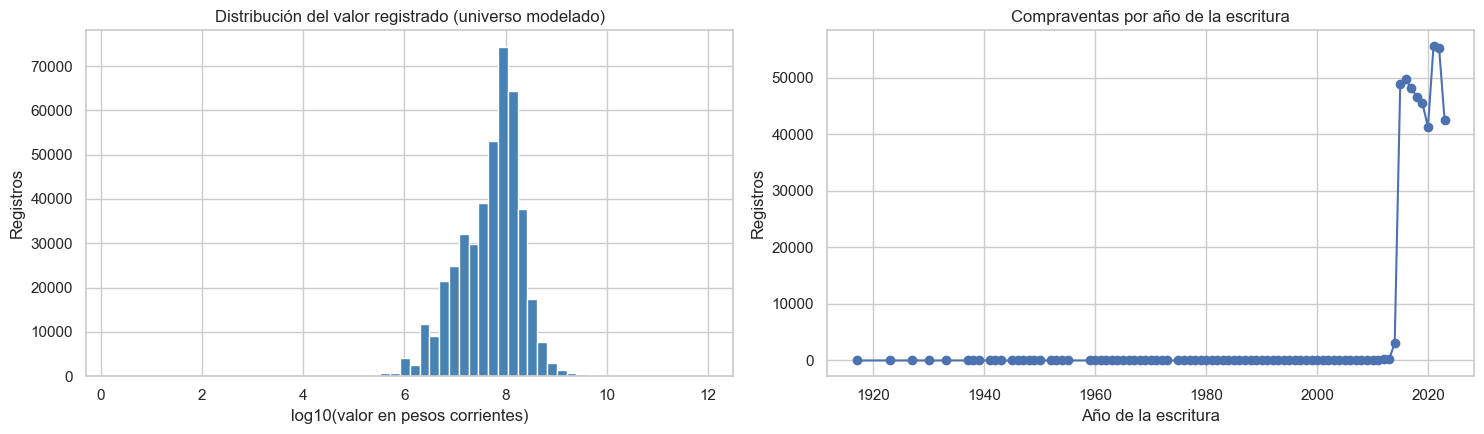

In [4]:
resumen_valor = (u["valor"] / 1e6).describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).to_frame("valor (millones de pesos corrientes)")
display(resumen_valor)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].hist(np.log10(u["valor"]), bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("Distribución del valor registrado (universo modelado)")
axes[0].set_xlabel("log10(valor en pesos corrientes)")
axes[0].set_ylabel("Registros")
por_anio = u.groupby("anio_escritura").size()
axes[1].plot(por_anio.index.astype(int), por_anio.values, marker="o")
axes[1].set_title("Compraventas por año de la escritura")
axes[1].set_xlabel("Año de la escritura")
axes[1].set_ylabel("Registros")
plt.tight_layout()
plt.show()

## 3. Segmentación

Volumen y valor por departamento, municipio y zona. **Advertencia:** las medianas de valor no son comparables entre territorios como si fueran precios, porque la base no trae área ni tipo de inmueble; una mediana más alta puede reflejar inmuebles más grandes o de otro tipo.

In [5]:
# Tabla de contingencia: registros por departamento y año de la escritura
display(pd.crosstab(u["departamento"], u["anio_escritura"], margins=True, margins_name="Total"))

# Tabla resumen por departamento (medidas robustas)
tabla_departamento = u.groupby("departamento").agg(
    registros=("pk", "size"),
    municipios=("municipio", "nunique"),
    folios=("matricula", "nunique"),
    valor_p25_mill=("valor", lambda s: s.quantile(0.25) / 1e6),
    valor_mediano_mill=("valor", lambda s: s.median() / 1e6),
    valor_p75_mill=("valor", lambda s: s.quantile(0.75) / 1e6),
)
tabla_departamento["% en paquete"] = u.groupby("departamento")["escritura_paquete"].mean() * 100
display(tabla_departamento)

anio_escritura,1917,1923,1927,1930,1933,1937,1938,1939,1941,1942,1943,1945,1946,1947,1948,1949,1950,1952,1953,1954,1955,1959,1960,1961,1962,1963,1964,1965,1966,1967,...,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Total
departamento,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CALDAS,0,1,1,1,0,2,1,1,0,2,0,1,3,2,2,3,2,2,1,2,1,1,3,3,1,1,0,2,0,4,...,6,8,9,5,11,5,4,12,8,15,17,15,19,13,22,24,36,52,68,803,15909,14958,14496,14379,13801,12567,16581,17127,12507,133552
QUINDÍO,1,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...,1,0,1,2,1,2,0,1,2,2,2,1,5,6,18,6,11,13,19,689,12975,13859,12784,12588,12022,11407,15002,16011,11987,119469
RISARALDA,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,2,1,0,0,0,0,1,1,1,1,0,1,1,...,3,7,5,10,7,4,11,13,19,20,28,33,43,41,53,60,56,110,112,1579,20001,20882,20864,19608,19647,17264,23981,22135,17997,184627
Total,1,1,1,1,1,2,1,1,1,2,1,1,3,2,3,3,3,4,2,2,1,1,3,4,2,2,1,2,2,5,...,10,15,15,17,19,11,15,26,29,37,47,49,67,60,93,90,103,175,199,3071,48885,49699,48144,46575,45470,41238,55564,55273,42491,437648


,registros,municipios,folios,valor_p25_mill,valor_mediano_mill,valor_p75_mill,% en paquete
departamento,,,,,,,
CALDAS,133552,27,105961,13.25,50.00,128.00,37.51
QUINDÍO,119469,12,92310,19.00,60.00,118.50,40.50
RISARALDA,184627,14,144753,28.00,78.30,130.50,33.35


registros  % del universo  % acumulado
departamento municipio                                                  
RISARALDA    PEREIRA                  97754           22.34        22.34
QUINDÍO      ARMENIA                  90662           20.72        43.05
CALDAS       MANIZALES                69484           15.88        58.93
RISARALDA    DOSQUEBRADAS             52958           12.10        71.03
             SANTA ROSA DE CABAL      19136            4.37        75.40
CALDAS       VILLAMARÍA                9712            2.22        77.62
             CHINCHINÁ                 6376            1.46        79.08
QUINDÍO      MONTENEGRO                6092            1.39        80.47
CALDAS       AGUADAS                   5400            1.23        81.70
QUINDÍO      CIRCASIA                  5154            1.18        82.88

,registros,valor_mediano_mill
tipo_predio_zona,,
RURAL,104745,50.00
SIN INFORMACION,1256,48.26
URBANO,331647,70.00


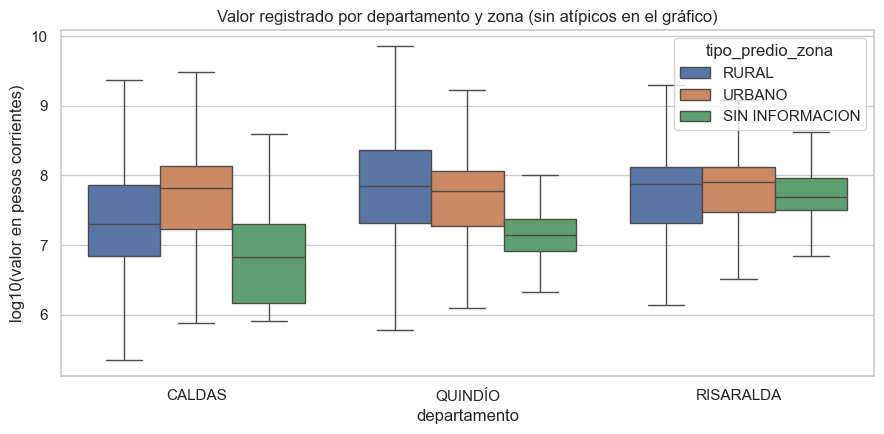

In [6]:
# Concentración territorial: municipios con más compraventas
top_municipios = (u.groupby(["departamento", "municipio"]).size()
                  .sort_values(ascending=False).rename("registros").to_frame())
top_municipios["% del universo"] = top_municipios["registros"] / len(u) * 100
top_municipios["% acumulado"] = top_municipios["% del universo"].cumsum()
display(top_municipios.head(10))

# Zona urbana o rural y valor por departamento
display(u.groupby("tipo_predio_zona").agg(registros=("pk", "size"),
                                          valor_mediano_mill=("valor", lambda s: s.median() / 1e6)))
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=u.assign(log_valor=np.log10(u["valor"])), x="departamento", y="log_valor",
            hue="tipo_predio_zona", showfliers=False, ax=ax)
ax.set_title("Valor registrado por departamento y zona (sin atípicos en el gráfico)")
ax.set_ylabel("log10(valor en pesos corrientes)")
plt.tight_layout()
plt.show()

## 4. Extracción de variables: ventas repetidas del mismo folio

El índice de ventas repetidas compara el valor del mismo folio en dos momentos. Aquí se construyen los pares (venta anterior, venta actual) dentro de los **candidatos para el índice** (sección 1), ordenados por la fecha de la escritura. De cada par se derivan los meses entre ventas y el cambio de valor.

Los pares con menos de 12 meses no se anualizan: con poco tiempo entre ventas, el cambio de valor refleja más la operación (por ejemplo, una reventa rápida) que la evolución del mercado.

Pares de ventas repetidas: 66,051 en 50,933 folios
Candidatos para el índice: 338,941


,pares,folios,meses_mediana,pct_menos_12_meses,crecimiento_anual_mediano_pct
departamento,,,,,
CALDAS,19659,15104,21.45,31.98,8.47
QUINDÍO,17815,13632,23.59,30.01,6.20
RISARALDA,28577,22197,23.19,29.48,6.98


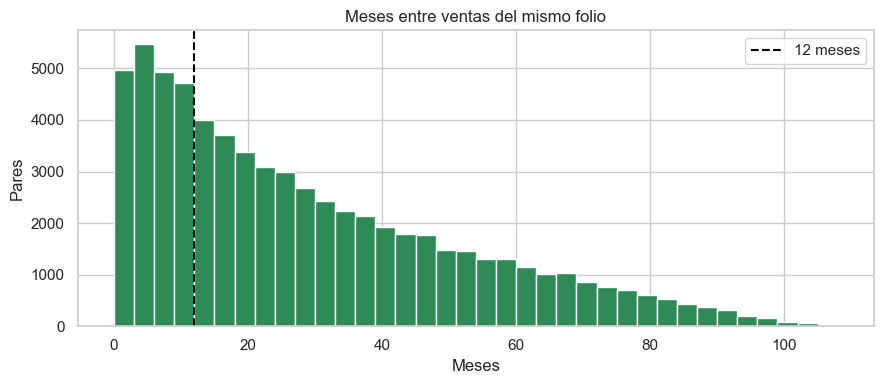

In [7]:
c = d[candidatos].sort_values(["matricula", "fecha_escritura"]).copy()
grupo = c.groupby("matricula")
c["fecha_anterior"] = grupo["fecha_escritura"].shift()
c["valor_anterior"] = grupo["valor"].shift()
pares = c.dropna(subset=["fecha_anterior"]).copy()
pares["meses_entre_ventas"] = (pares["fecha_escritura"] - pares["fecha_anterior"]).dt.days / 30.44
pares["razon_valor"] = pares["valor"] / pares["valor_anterior"]
largos = pares["meses_entre_ventas"] >= 12
pares["crecimiento_anual"] = np.where(
    largos, pares["razon_valor"] ** (12 / pares["meses_entre_ventas"]) - 1, np.nan)

resumen_pares = pares.groupby("departamento").agg(
    pares=("pk", "size"),
    folios=("matricula", "nunique"),
    meses_mediana=("meses_entre_ventas", "median"),
    pct_menos_12_meses=("meses_entre_ventas", lambda s: (s < 12).mean() * 100),
    crecimiento_anual_mediano_pct=("crecimiento_anual", lambda s: s.median() * 100),
)
print(f"Pares de ventas repetidas: {len(pares):,} en {pares['matricula'].nunique():,} folios")
print(f"Candidatos para el índice: {int(candidatos.sum()):,}")
display(resumen_pares)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(pares["meses_entre_ventas"], bins=np.arange(0, 110, 3), color="seagreen", edgecolor="white")
ax.axvline(12, color="black", linestyle="--", label="12 meses")
ax.set_title("Meses entre ventas del mismo folio")
ax.set_xlabel("Meses")
ax.set_ylabel("Pares")
ax.legend()
plt.tight_layout()
plt.show()

**Para interpretar** (a completar con los resultados reales): el crecimiento anual está en pesos corrientes, así que incluye la inflación; no debe leerse como valorización real hasta deflactar con el IPC. Una proporción alta de pares con menos de 12 meses indica que, con poca historia, el índice tiende a capturar reventas rápidas más que la evolución de los precios.

## 5. Adición de nueva información: IPC

*Pendiente.* La Parte I (sección 1.1) incorpora el IPC del DANE para expresar los valores en pesos constantes. Cuando esté disponible, se agrega aquí una columna `valor_constante` y se repiten las secciones 2 y 4 con ella. Nota: se usa el IPC general; el componente de vivienda del IPC mide arriendos, no precios de compraventa.

## 6. Conclusiones del entendimiento de los datos

*Pendiente.* Debe responder lo que pide el entregable: coherencia de estos resultados frente a la problemática de negocio y a los requerimientos de la Guía 2.

## 7. Exportación

Se guardan los pares de ventas repetidas para las etapas de modelado.

In [8]:
columnas_pares = ["matricula", "departamento", "municipio", "divipola", "fecha_anterior", "valor_anterior",
                  "fecha_escritura", "valor", "meses_entre_ventas", "razon_valor", "crecimiento_anual"]
salida = RAIZ / "data/processed/ventas_repetidas.csv"
pares[columnas_pares].to_csv(salida, index=False)
print(f"Guardado: {salida.relative_to(RAIZ)} ({len(pares):,} pares)")

Guardado: data\processed\ventas_repetidas.csv (66,051 pares)
